In [35]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [36]:
csv_path = "data/US_youtube_trending_data.csv"

yt_df = pd.read_csv(csv_path)

This dataset uses a supplemental JSON to define categories. I need to take a look at the categories first so I can extract the videos that are relelvant to Digital Dash (education, comp sci, and animation if it's there).

To make life easier, I'll start by mapping the category titles to thier corresponding IDs in the main dataframe, `yt-df`.

In [37]:
import json
with open("data/US_category_id.json") as file:
    categories = json.load(file)

category_map = {
    item["id"]: item["snippet"]["title"]
    for item in categories["items"]
}

yt_df["category_name"] = yt_df["categoryId"].astype(str).map(category_map)
yt_df

,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description,category_name
0,3C66w5Z0ixs,I ASKED HER TO BE MY GIRLFRIEND...,2020-08-11T19:20:14Z,UCvtRTOMP2TqYqu51xNrqAzg,Brawadis,22,2020-08-12T00:00:00Z,brawadis|prank|basketball|skits|ghost|funny vi...,1514614,156908,5855,35313,https://i.ytimg.com/vi/3C66w5Z0ixs/default.jpg,False,False,SUBSCRIBE to BRAWADIS ▶ http://bit.ly/Subscrib...,People & Blogs
1,M9Pmf9AB4Mo,Apex Legends | Stories from the Outlands – “Th...,2020-08-11T17:00:10Z,UC0ZV6M2THA81QT9hrVWJG3A,Apex Legends,20,2020-08-12T00:00:00Z,Apex Legends|Apex Legends characters|new Apex ...,2381688,146739,2794,16549,https://i.ytimg.com/vi/M9Pmf9AB4Mo/default.jpg,False,False,"While running her own modding shop, Ramya Pare...",Gaming
2,J78aPJ3VyNs,I left youtube for a month and THIS is what ha...,2020-08-11T16:34:06Z,UCYzPXprvl5Y-Sf0g4vX-m6g,jacksepticeye,24,2020-08-12T00:00:00Z,jacksepticeye|funny|funny meme|memes|jacksepti...,2038853,353787,2628,40221,https://i.ytimg.com/vi/J78aPJ3VyNs/default.jpg,False,False,I left youtube for a month and this is what ha...,Entertainment
3,kXLn3HkpjaA,XXL 2020 Freshman Class Revealed - Official An...,2020-08-11T16:38:55Z,UCbg_UMjlHJg_19SZckaKajg,XXL,10,2020-08-12T00:00:00Z,xxl freshman|xxl freshmen|2020 xxl freshman|20...,496771,23251,1856,7647,https://i.ytimg.com/vi/kXLn3HkpjaA/default.jpg,False,False,Subscribe to XXL → http://bit.ly/subscribe-xxl...,Music
4,VIUo6yapDbc,Ultimate DIY Home Movie Theater for The LaBran...,2020-08-11T15:10:05Z,UCDVPcEbVLQgLZX0Rt6jo34A,Mr. Kate,26,2020-08-12T00:00:00Z,The LaBrant Family|DIY|Interior Design|Makeove...,1123889,45802,964,2196,https://i.ytimg.com/vi/VIUo6yapDbc/default.jpg,False,False,Transforming The LaBrant Family's empty white ...,Howto & Style
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268782,4-uXvx5M7XA,Total solar eclipse causing tourism boost acro...,2024-04-08T15:55:44Z,UClwddNv0Cr6SIEGkzVK886w,FOX 9 Minneapolis-St. Paul,25,2024-04-15T00:00:00Z,morning-news|Eclipses|travel|travel news|weath...,359130,2345,0,581,https://i.ytimg.com/vi/4-uXvx5M7XA/default.jpg,False,False,Millions of people in the United States are tr...,News & Politics
268783,aFsfJYWpqII,Food Delivery Apps: Last Week Tonight with Joh...,2024-04-04T11:00:02Z,UC3XTzVzaHQEd30rQbuvCtTQ,LastWeekTonight,24,2024-04-15T00:00:00Z,[None],3998181,107811,0,10335,https://i.ytimg.com/vi/aFsfJYWpqII/default.jpg,False,False,"John Oliver discusses food delivery apps, how ...",Entertainment
268784,pRAsQss17xs,12 Things NO-ONE Tells You About Japan | Feat....,2024-04-07T14:53:25Z,UCHL9bfHTxCMi-7vfxQ-AYtg,Abroad in Japan,24,2024-04-15T00:00:00Z,japan|cdawgva|abroad in japan|trash taste,873960,41941,0,1918,https://i.ytimg.com/vi/pRAsQss17xs/default.jpg,False,False,We reveal 12 things no-one tells you to expect...,Entertainment
268785,84QeCD7y_Ds,Buying My Dream Car At 21,2024-04-07T18:00:03Z,UChQ-d14tHB62nskossxO0tw,Joe Fazer,24,2024-04-15T00:00:00Z,gym|youtube|bodybuilder|powerlifter|vlog|vlogg...,535842,42845,0,1852,https://i.ytimg.com/vi/84QeCD7y_Ds/default.jpg,False,False,Use code JOE at checkout to get discounts on M...,Entertainment


I'm interested in these categories:
- Education
- Science & Technology

I'll need to take a look at a few of the 'Film & Animation,' 'Anime/Animation,' and 'Shows' videos to check whether those are fictional media (such as Amazing Digital Circus and other YouTube-published titles), or commentary. I'm not interested in the performance of commentary channels. 

In [38]:
yt_category_grouped = yt_df.groupby("category_name")

yt_category_grouped.groups.keys()

dict_keys(['Autos & Vehicles', 'Comedy', 'Education', 'Entertainment', 'Film & Animation', 'Gaming', 'Howto & Style', 'Music', 'News & Politics', 'Nonprofits & Activism', 'People & Blogs', 'Pets & Animals', 'Science & Technology', 'Sports', 'Travel & Events'])

Looks like this dataset doesn't actually have any 'Anime/Animation,' or 'Shows' videos. The CSV I'm working with is from a collection of datasets holding trending videos in a bunch of other countries, so my assumption is that the supplemental JSON has categories that just aren't trending in the US. 

Anyways, let's see whether 'Film & Animation' should be looked at.

In [39]:
yt_category_grouped.get_group("Film & Animation").head()


,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description,category_name
21,5WjcDji3xYc,Honest Trailers | Avatar: The Last Airbender,2020-08-11T17:03:59Z,UCOpcACMWblDls9Z6GERVi1A,Screen Junkies,1,2020-08-12T00:00:00Z,screenjunkies|screen junkies|honest trailers|h...,833369,50181,1120,4634,https://i.ytimg.com/vi/5WjcDji3xYc/default.jpg,False,False,►►Subscribe to ScreenJunkies!► https://fandom....,Film & Animation
27,z5l8ovbw_6M,Don't be a Tourist,2020-08-10T21:28:49Z,UCDQBZcjYKP1J1Nu-Y0_D37Q,Tabbes,1,2020-08-12T00:00:00Z,drawing|humor|storytime animation|story|slice ...,1061892,117220,876,9311,https://i.ytimg.com/vi/z5l8ovbw_6M/default.jpg,False,False,This one is for all you full time travelersEMA...,Film & Animation
50,yVdH3QacEXc,Selena Gomez - This is the Year (Official Prem...,2020-08-10T16:32:06Z,UCPNxhDvTcytIdvwXWAm43cA,Selena Gomez,1,2020-08-12T00:00:00Z,Selena Gomez|David Henrie|Dixie D’Amelio|Charl...,1523818,163684,2377,9845,https://i.ytimg.com/vi/yVdH3QacEXc/default.jpg,False,False,Get your tickets here: https://thisistheyear.f...,Film & Animation
135,A5RHu1lTv14,Satina Wants a Bedtime Story (SATINA SHORT #1),2020-08-08T16:00:04Z,UC1fjSSxPEEHb7WqAdd6xChQ,Hannah Daigle,1,2020-08-12T00:00:00Z,[None],605317,101243,345,5605,https://i.ytimg.com/vi/A5RHu1lTv14/default.jpg,False,False,MERCH STORE: https://sharkrobot.com/collection...,Film & Animation
143,PORP0q8nThs,Getting Suspended In High School,2020-08-07T20:52:37Z,UCRfg0SWjIHm_h95e4V8X5og,Young Don The Sauce God,1,2020-08-12T00:00:00Z,young don the sauce god|animations|animated|st...,741546,66329,523,4273,https://i.ytimg.com/vi/PORP0q8nThs/default.jpg,False,False,No Risk. No Reward. Getting Suspended In High ...,Film & Animation


So, 3 of those are animated or animatics! 2 of those 3 have "animation" in the tags, but the third has no tags. I don't think it's worth it to parse the tags to add just a couple of videos to my analysis, so I'll skip this category for now.

Moving on: I already have the videos grouped by category, so poking around the 'Education' and 'Science & Technology' categories should be pretty easy, wahoo!

In [40]:
yt_category_grouped.get_group("Education").head()

,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description,category_name
7,ua4QMFQATco,CGP Grey was WRONG,2020-08-11T17:15:11Z,UC2C_jShtL725hvbm1arSV9w,CGP Grey,27,2020-08-12T00:00:00Z,cgpgrey|education|hello internet,1050143,89190,854,6455,https://i.ytimg.com/vi/ua4QMFQATco/default.jpg,False,False,‣ What Was TEKOI: https://www.youtube.com/watc...,Education
30,9nidKH8cM38,TAXI CAB SLAYER KILLS 'TO KNOW HOW IT FEELS',2020-08-11T20:00:45Z,UCFMbX7frWZfuWdjAML0babA,Eleanor Neale,27,2020-08-12T00:00:00Z,eleanor|neale|eleanor neale|eleanor neale true...,236830,16423,209,1642,https://i.ytimg.com/vi/9nidKH8cM38/default.jpg,False,False,The first 1000 people to click the link will g...,Education
32,GYeKX_LPY9U,15 Friendliest Sea Creatures Around The World,2020-08-11T16:00:07Z,UCTDJ9osmaIty0MVkUZymVmQ,Amerikano,27,2020-08-12T00:00:00Z,friendliest|sea|creatures|around|world|ocean|a...,880035,16970,626,881,https://i.ytimg.com/vi/GYeKX_LPY9U/default.jpg,False,False,It’s easy to forget just how dangerous the oce...,Education
94,JXzk8G9aXI8,Avatar Intro but with Animals,2020-08-03T21:51:14Z,UCa0LID3WQdj-bd5KiI-34vw,BLTW,27,2020-08-12T00:00:00Z,avatar|avatar the last airbender|avatar meme|a...,1048314,51361,891,965,https://i.ytimg.com/vi/JXzk8G9aXI8/default.jpg,False,False,"Long ago ⏱, the four4️⃣ pets🐶 lived together i...",Education
136,tqvEEqWGCyE,The (Real) Delusion That You're a Corpse,2020-08-08T14:00:43Z,UCi5iiEyLwSLvlqnMi02u5gQ,Ask A Mortician,27,2020-08-12T00:00:00Z,Cotard's syndrome|mental illness|dead|walking ...,324208,26377,277,2801,https://i.ytimg.com/vi/tqvEEqWGCyE/default.jpg,False,False,More than just feeling a little dead inside. T...,Education


In [41]:
yt_category_grouped.get_group("Science & Technology").head()

,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description,category_name
20,vePc5V4h_kg,Shark Attack Test- Human Blood vs. Fish Blood,2020-08-09T16:00:11Z,UCY1kMZp36IQSyNx_9h4mpCg,Mark Rober,28,2020-08-12T00:00:00Z,sharks|sharkweek|jaws|shark attack|blood in wa...,14684474,544038,15818,33507,https://i.ytimg.com/vi/vePc5V4h_kg/default.jpg,False,False,I personally got in the water and tested if Sh...,Science & Technology
42,zHPVGSwLhcg,Unboxing Apple's $129 Luxury Cable,2020-08-11T14:42:43Z,UCsTcErHg8oDvUnTzoqsYeNw,Unbox Therapy,28,2020-08-12T00:00:00Z,unbox therapy|unboxtherapy|tech|technology|gad...,997102,60993,8847,13810,https://i.ytimg.com/vi/zHPVGSwLhcg/default.jpg,False,False,ShhhhFOLLOW ME IN THESE PLACES FOR UPDATES\rTw...,Science & Technology
66,KmVG1Yx1kwQ,3 DAYS with the Samsung Galaxy Note 20 Ultra! ...,2020-08-10T18:28:55Z,UCzlXf-yUIaOpOjEjPrOO9TA,The Tech Chap,28,2020-08-12T00:00:00Z,note 20 ultra|galaxy note 20 ultra|samsung gal...,285517,6771,254,1463,https://i.ytimg.com/vi/KmVG1Yx1kwQ/default.jpg,False,False,What's it like using the Samsung Galaxy Note 2...,Science & Technology
158,Djy3WNLz_mM,The coronavirus is mutating. Now what?,2020-08-07T12:00:04Z,UCLXo7UDZvByw2ixzpQCufnA,Vox,28,2020-08-12T00:00:00Z,vox.com|vox|explain|coronavirus|quibi|cleo abr...,1973800,39140,6047,7988,https://i.ytimg.com/vi/Djy3WNLz_mM/default.jpg,False,False,"The coronavirus is mutating, and scientists ar...",Science & Technology
224,CqRKOY4Cgvw,The new Surface Duo. Do one better.,2020-08-12T12:12:40Z,UCGS474QoP8SCnSo6hOCaayA,Microsoft Surface,28,2020-08-13T00:00:00Z,Microsoft|Microsoft Surface|Surface phone|dual...,375759,10588,613,1823,https://i.ytimg.com/vi/CqRKOY4Cgvw/default.jpg,False,False,Surface innovation comes to a mobile device. I...,Science & Technology


This isn't very many videos. Let's see how these categories stack up against others.

In [42]:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html
category_stats = (
    yt_df.groupby("category_name")
    .agg(
        trending_records=("video_id", "size"),
        unique_videos=("video_id", "nunique"),
        unique_channels=("channelId", "nunique"),
    ).sort_values("unique_videos", ascending=False)
)

category_stats["share_of_videos"] = (category_stats["unique_videos"]/category_stats["unique_videos"].sum() * 100).round(2)
category_stats

,trending_records,unique_videos,unique_channels,share_of_videos
category_name,,,,
Gaming,53242,9437,1682,20.01
Entertainment,53934,9195,1719,19.49
Music,43398,7353,1759,15.59
Sports,31327,6074,668,12.88
People & Blogs,22653,4042,1081,8.57
Comedy,13183,2254,391,4.78
Film & Animation,10923,1839,381,3.90
News & Politics,9669,1733,364,3.67
Science & Technology,8156,1425,222,3.02


In [43]:
sorted_stats = category_stats["unique_videos"].sort_values()    

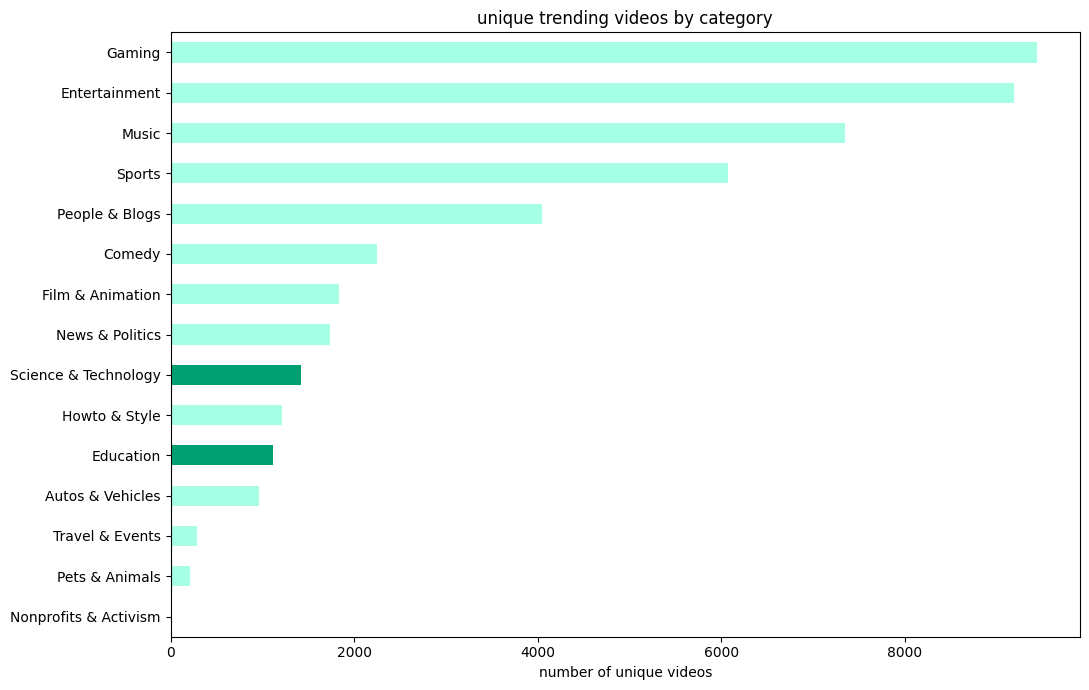

In [44]:
# pick colors for the bars in the chart that highlight important categories 
default_colors = ["#a5ffe4", "#ffe6ba", "#ffc7c7", "#fff6bf"]
highlight_colors = ["#00a070", "#ffa200", "#c00000", "#ffd900"]
highlight_categories = {
    "Education": highlight_colors[0],
    "Science & Technology": highlight_colors[0]
}
colors = [highlight_categories.get(category, default_colors[0]) for category in sorted_stats.index]

ax = sorted_stats.plot.barh(
    figsize=(11, 7),
    color=colors
)

ax.set(
    title="unique trending videos by category",
    xlabel="number of unique videos",
    ylabel=""
)

plt.tight_layout()
plt.show()

I wonder whether this distribution changes at all over time. Let's try a line plot - months in the x-axis, number of trending videos in the y-axis, each line corresponding to a different category.

In [45]:
# published_at column looks like "2020-08-11T16:38:55Z"
# need to extract the month portion
published_at_df = yt_df[["publishedAt", "category_name"]].copy()
published_at_df["publishedAt"] = pd.to_datetime(published_at_df["publishedAt"], format="ISO8601")
published_at_df["published_month"] = published_at_df["publishedAt"].dt.strftime("%b")   # gets months as strings
# published_at_df = published_at_df.drop(columns=["publishedAt"])
published_at_df


,publishedAt,category_name,published_month
0,2020-08-11 19:20:14+00:00,People & Blogs,Aug
1,2020-08-11 17:00:10+00:00,Gaming,Aug
2,2020-08-11 16:34:06+00:00,Entertainment,Aug
3,2020-08-11 16:38:55+00:00,Music,Aug
4,2020-08-11 15:10:05+00:00,Howto & Style,Aug
...,...,...,...
268782,2024-04-08 15:55:44+00:00,News & Politics,Apr
268783,2024-04-04 11:00:02+00:00,Entertainment,Apr
268784,2024-04-07 14:53:25+00:00,Entertainment,Apr
268785,2024-04-07 18:00:03+00:00,Entertainment,Apr


In [46]:
# found a cleaner approach than the by-hand agg I did earlier: 
#   https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html
published_at_stats = pd.crosstab(published_at_df["published_month"], published_at_df["category_name"])
published_at_stats

category_name,Autos & Vehicles,Comedy,Education,Entertainment,Film & Animation,Gaming,Howto & Style,Music,News & Politics,Nonprofits & Activism,People & Blogs,Pets & Animals,Science & Technology,Sports,Travel & Events
published_month,,,,,,,,,,,,,,,
Apr,361,850,405,4267,839,4124,493,3249,635,32,1737,70,546,2333,135
Aug,472,1134,595,4466,997,4695,564,4302,968,0,1847,127,552,2759,103
Dec,581,1462,779,5386,1231,4856,671,3593,708,0,2232,116,791,2817,182
Feb,624,1089,587,4799,918,4819,565,3286,976,0,2067,121,665,2627,156
Jan,565,1192,588,4887,869,4238,796,3131,1177,0,2229,112,718,3282,247
Jul,370,828,445,3867,746,3885,394,3112,456,5,1510,84,496,1914,94
Jun,427,834,444,3946,808,5032,433,3115,589,10,1635,91,562,2135,119
Mar,456,1179,572,4843,963,4918,665,4198,1106,0,2091,104,666,2553,121
May,309,820,448,3842,713,3658,388,3312,684,22,1343,67,469,2036,86


In [47]:
# I really want the month names, not number, but I still want them in calendar order
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# can use reindex: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reindex.html 
published_at_stats = published_at_stats.reindex(month_order)

# might not be the most pythonic way to do this

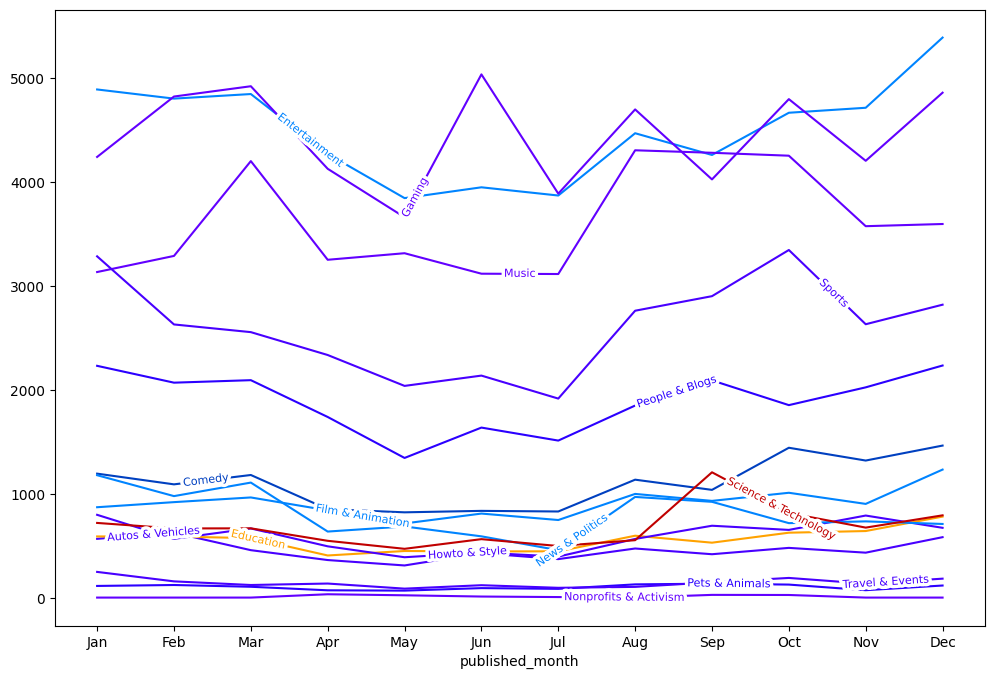

In [48]:

import random
from labellines import labelLines

line_colors = ["#2b00ff", "#0084ff", "#0050a0", "#4800ff", "#0040c0", "#6200ff"]
highlight_lines = {
    "Education": highlight_colors[1],
    "Science & Technology": highlight_colors[2]
}

ax = published_at_stats.plot.line(
    figsize=(12, 8),
    xticks=range(len(published_at_stats.index)),
    legend=False,
    color=[highlight_lines.get(category, random.choice(line_colors)) for category in published_at_stats.columns]
)

labelLines(ax.get_lines(), align=True, fontsize=8)
plt.show()


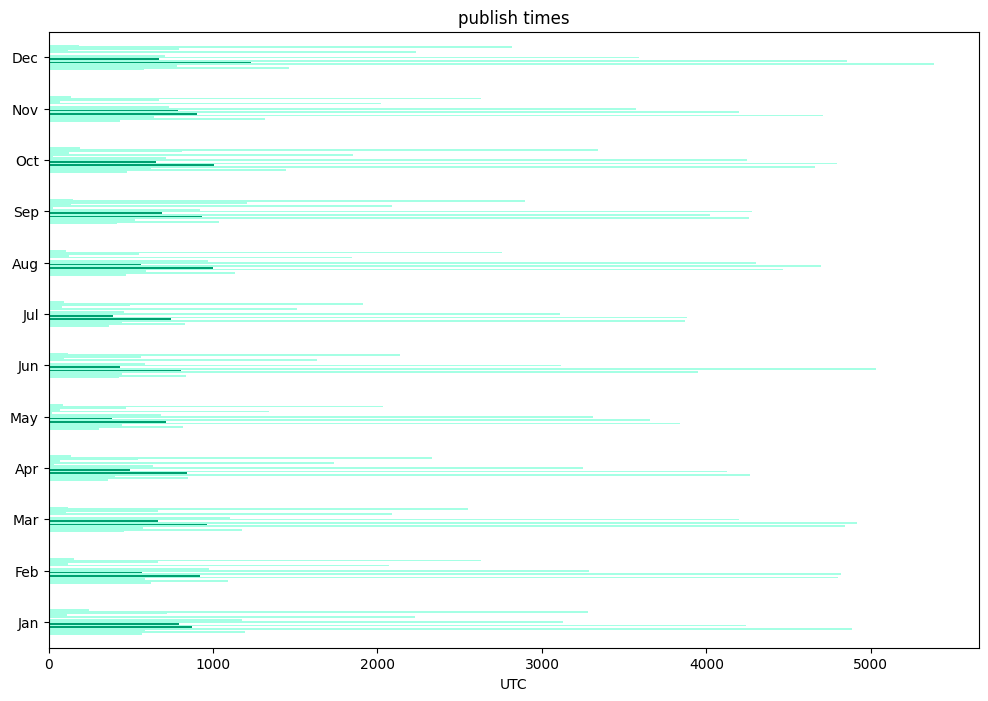

In [ ]:
ax4 = published_at_stats.plot.barh(
    figsize=(12, 8),
    legend=False,
    color=colors
)

plt.show()

Neat, looks like September has been a good month for Science & Technology, and in general it seems like things tend to trend from Sept-Jan, peaking in Dec-Jan. 

I want to check out the thumbnails now. I'll try to load a bunch of them in a grid.

In [49]:
import ipywidgets as widgets
from IPython.display import Image, display

# grab image URLs for the videos in Science & Technology and Education categories
urls = yt_category_grouped.get_group("Science & Technology").head()["thumbnail_link"].tolist() + \
       yt_category_grouped.get_group("Education").head()["thumbnail_link"].tolist()

# [widgets.Image(value=Image(url=url, embed=True).data, format="png", width=150) for url in urls]
image_widgets = [] 

for url in urls:
    try:
        image_widgets.append(widgets.Image(value=Image(url=url, embed=True).data, format="jpeg", width=150))
    except:
        continue

columns = 6
rows = [widgets.HBox(image_widgets[i : i + columns]) for i in range(0, len(image_widgets), columns)]

grid = widgets.VBox(rows)
display(grid)
widgets

<module 'ipywidgets' from '/Users/wpp12142/Code/yt-data/venv/lib/python3.9/site-packages/ipywidgets/__init__.py'>

Now, here's some from Gaming and Entertainment, the top two trending categories.

In [50]:
# grab image URLs for the top 48 videos in Gaming and Entertainment categories
urls = yt_category_grouped.get_group("Gaming").head(24)["thumbnail_link"].tolist() + \
       yt_category_grouped.get_group("Entertainment").head(24)["thumbnail_link"].tolist()

# [widgets.Image(value=Image(url=url, embed=True).data, format="png", width=150) for url in urls]
image_widgets = [] 

for url in urls:
    try:
        image_widgets.append(widgets.Image(value=Image(url=url, embed=True).data, format="jpeg", width=150))
    except:
        continue

columns = 6
rows = [widgets.HBox(image_widgets[i : i + columns]) for i in range(0, len(image_widgets), columns)]

grid = widgets.VBox(rows)
display(grid)
widgets

<module 'ipywidgets' from '/Users/wpp12142/Code/yt-data/venv/lib/python3.9/site-packages/ipywidgets/__init__.py'>

I want to check out TOD

In [54]:
published_time_df = yt_df[["publishedAt", "category_name"]].copy()
published_time_df["publishedAt"] = pd.to_datetime(published_at_df["publishedAt"], format="ISO8601")
published_time_df["published_time"] = published_at_df["publishedAt"].dt.hour
published_time_df

,publishedAt,category_name,published_time
0,2020-08-11 19:20:14+00:00,People & Blogs,19
1,2020-08-11 17:00:10+00:00,Gaming,17
2,2020-08-11 16:34:06+00:00,Entertainment,16
3,2020-08-11 16:38:55+00:00,Music,16
4,2020-08-11 15:10:05+00:00,Howto & Style,15
...,...,...,...
268782,2024-04-08 15:55:44+00:00,News & Politics,15
268783,2024-04-04 11:00:02+00:00,Entertainment,11
268784,2024-04-07 14:53:25+00:00,Entertainment,14
268785,2024-04-07 18:00:03+00:00,Entertainment,18


In [55]:
published_time_stats = pd.crosstab(published_time_df["published_time"], published_time_df["category_name"])
published_time_stats

category_name,Autos & Vehicles,Comedy,Education,Entertainment,Film & Animation,Gaming,Howto & Style,Music,News & Politics,Nonprofits & Activism,People & Blogs,Pets & Animals,Science & Technology,Sports,Travel & Events
published_time,,,,,,,,,,,,,,,
0,220,398,111,2027,266,1701,257,2507,691,6,1110,19,198,1824,23
1,178,328,62,2005,350,1451,259,1089,483,19,925,11,205,1513,11
2,120,251,28,1394,214,1174,114,763,414,4,568,5,170,1562,14
3,63,225,34,1234,185,670,87,980,529,9,384,5,90,2159,27
4,46,284,40,1086,108,731,57,7291,330,9,513,0,106,2153,11
5,36,234,21,804,151,332,30,3240,210,0,215,0,73,1773,12
6,5,124,41,531,95,302,92,346,126,4,117,5,49,923,16
7,5,112,25,551,53,358,15,290,95,0,103,2,58,479,23
8,36,54,18,453,29,857,20,551,83,0,70,6,71,273,5


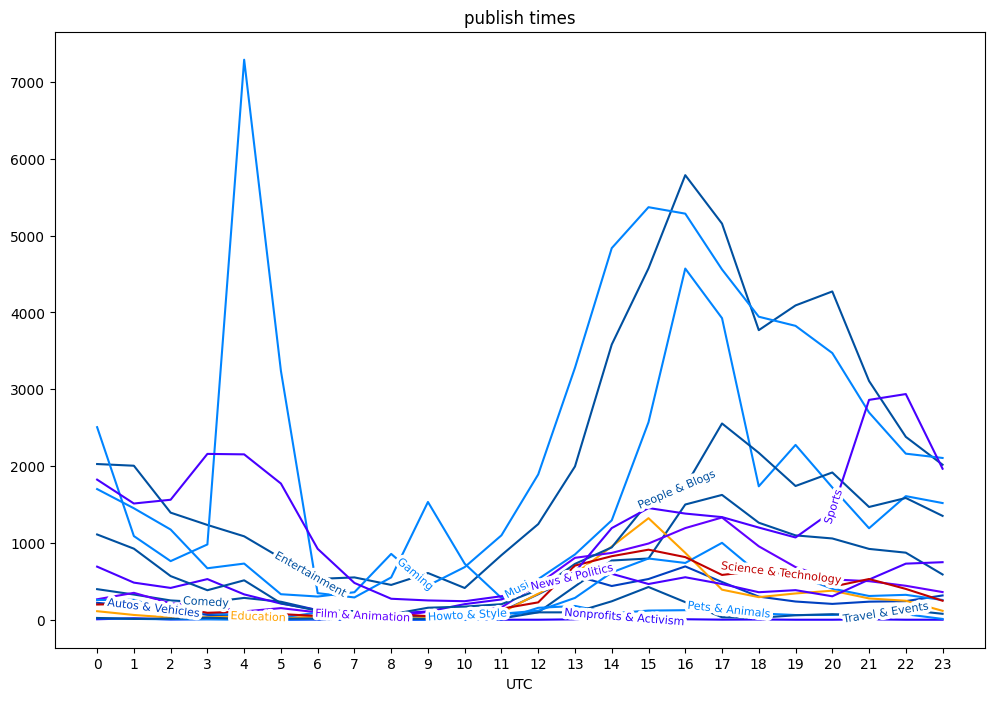

In [60]:
ax2 = published_time_stats.plot.line(
    figsize=(12, 8),
    xticks=range(len(published_time_stats.index)),
    legend=False,
    color=[highlight_lines.get(category, random.choice(line_colors)) for category in published_time_stats.columns]
)

ax2.set(
    title="publish times",
    xlabel="UTC",
    ylabel=""
)

labelLines(ax2.get_lines(), align=True, fontsize=8)
plt.show()

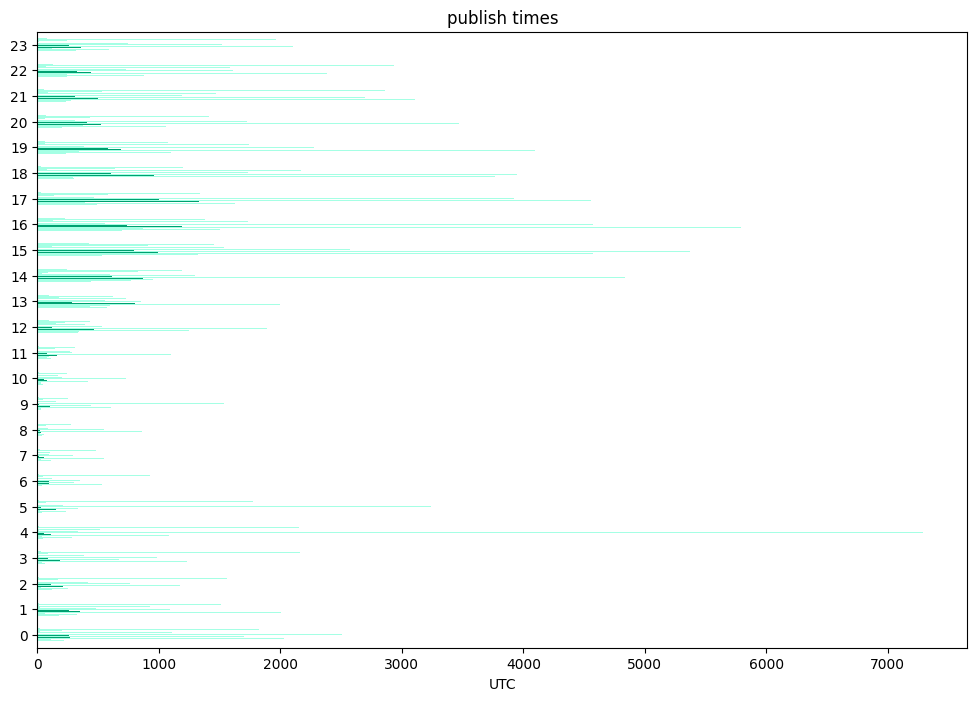

In [ ]:
ax3 = published_time_stats.plot.barh(
    figsize=(12, 8),
    legend=False,
    color=colors
)

ax3.set(
    title="publish times",
    xlabel="UTC",
    ylabel=""
)

plt.show()